## 1. Титульный лист

# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль:** 3 — Ансамблевые методы (базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn (IBM / Kaggle)

**Выполнил:** Черепанов Вячеслав Сергеевич      
**Группа:** ПКТб-23-1       
**Преподаватель:** Спирин Игорь Сергеевич  
**Репозиторий:** https://github.com/CherepanovVyacheslav/ml-course-cherepanov  
**Путь к работе:** `module-3-churn/notebook.ipynb`  
**Дата:** 28.10.2026


## 2. Введение

В работе рассматривается **бинарная классификация**: по характеристикам договора, платежей и используемых услуг определить, уйдёт ли клиент оператора связи (`Churn = 1`) или останется (`Churn = 0`). В отличие от регрессии, здесь предсказывается не числовая величина, а принадлежность одному из двух классов; дополнительным результатом служит вероятность ухода.

**Ансамблевые методы** объединяют результаты нескольких простых моделей. Такое объединение часто снижает нестабильность прогноза и позволяет учитывать сложные зависимости. Я сравню Random Forest (bagging) с тремя реализациями градиентного бустинга: XGBoost, LightGBM и CatBoost. Для них будут одинаковыми разделение данных и набор признаков.

**Главная метрика — ROC-AUC:** она показывает, насколько хорошо модель ранжирует клиентов по риску ухода при различных порогах. Дополнительно важно смотреть Recall (сколько фактически ушедших найдено), Precision (сколько помеченных как «уйдут» действительно ушли) и F1. Обычная Accuracy в условиях дисбаланса примерно 74/26 может быть обманчивой: модель, всегда отвечающая «останется», уже будет иметь высокую долю правильных ответов.

**Цели:** (1) выполнить EDA и корректную предобработку; (2) обучить и сопоставить четыре ансамбля, настроить LightGBM через Optuna; (3) объяснить результаты с помощью важностей признаков и SHAP, сохранить модели для последующего применения.

## 3. Теоретическая часть

### Ансамбль
Ансамбль — система из нескольких моделей, чьи ответы объединяются в итоговый прогноз. Идея заключается в том, что ошибки отдельных моделей могут частично компенсироваться. При этом ансамбль не гарантирует прирост качества: если все базовые модели ошибаются одинаково, объединение мало что исправит. Поэтому на практике его результат проверяют на данных, не участвовавших в обучении.

### Bagging и boosting
**Bagging** обучает несколько моделей параллельно на различных бутстрэп-выборках. В классификации их ответы обычно усредняют по вероятностям или объединяют голосованием. Это прежде всего помогает уменьшить дисперсию предсказаний. **Boosting**, наоборот, строит модели последовательно: каждая новая модель корректирует ошибки уже построенной композиции. Такая схема часто даёт высокую точность, но требует контроля глубины деревьев, темпа обучения и переобучения.

Для усреднения числовых прогнозов и взвешенной аддитивной композиции используются формулы:

$$H_{bag}(x)=\frac{1}{M}\sum_{m=1}^{M}h_m(x)$$

$$H_{boost}(x)=\sum_{m=1}^{M}\alpha_m h_m(x)$$

### Stacking
В отличие от bagging и boosting, stacking обучает отдельную метамодель на прогнозах нескольких базовых алгоритмов. Обычно используются вневыборочные прогнозы кросс-валидации: иначе метамодель может переобучиться на ответах моделей, видевших соответствующие наблюдения. В этой работе stacking указан как возможное улучшение, а обязательные алгоритмы обучаются и сравниваются отдельно.

### Random Forest
Random Forest — ансамбль деревьев решений, обучаемых на случайных выборках объектов и признаков. Случайность снижает сходство деревьев и делает агрегированный результат более устойчивым. Для несбалансированных классов можно использовать `class_weight='balanced'`, но качество всё равно оценивается отдельно по каждому классу.

### Градиентный бустинг
**XGBoost** поддерживает регуляризацию и различные ограничения сложности деревьев. **LightGBM** использует эффективное построение деревьев и хорошо подходит для подбора многих конфигураций. **CatBoost** особенно удобен для категориальных полей; в этой работе для честного сравнения все алгоритмы получают одну и ту же закодированную таблицу. Boosting сильнее чувствителен к гиперпараметрам, поэтому без валидации нельзя выбирать сложную модель лишь по обучающей точности.

### Optuna
Optuna автоматически ищет удачную комбинацию гиперпараметров. Метод TPE учитывает результаты уже выполненных испытаний и выбирает перспективные новые значения. Оценивать каждую конфигурацию следует на кросс-валидации **только внутри обучающей выборки**. Тестовая часть должна оставаться независимой до финальной оценки.

### SHAP
SHAP объясняет отдельный прогноз, распределяя вклад между признаками на основе идеи значений Шепли. **Summary/beeswarm** показывает вклад признаков на множестве клиентов; **waterfall** раскладывает прогноз конкретного клиента на отдельные слагаемые; **dependence** отображает, как SHAP-вклад меняется со значением признака. Для деревьев применяется `TreeExplainer`. SHAP объясняет поведение модели, но не доказывает причинно-следственную связь.

| Метод | Подход | Особенность | Что контролировать |
|---|---|---|---|
| Random Forest | Bagging | Усреднение независимых деревьев | Число деревьев, глубина |
| XGBoost | Boosting | Регуляризация и управление структурой | Скорость обучения, глубина |
| LightGBM | Boosting | Быстрое построение деревьев | Число листьев, глубина |
| CatBoost | Boosting | Удобная работа с категориями | Итерации, глубина, регуляризация |

## 4. Описание данных

**Источник:** [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn); исходная таблица также опубликована в [репозитории IBM](https://github.com/IBM/telco-customer-churn-on-icp4d). Это учебный набор из **7043 наблюдений и 21 столбца**: идентификатор клиента, 19 характеристик и целевая переменная `Churn`.

| Поле | Содержание | Особенность |
|---|---|---|
| `customerID` | Уникальный идентификатор клиента | Не использовать как признак |
| `tenure` | Стаж клиента в месяцах | Числовое значение |
| `MonthlyCharges` | Ежемесячный платёж | Числовое значение |
| `TotalCharges` | Накопленная сумма платежей | В исходном CSV текст; встречаются пустые строки |
| `Contract` | Тип договора | Категория |
| `InternetService` | Тип интернета | Категория |
| `Churn` | Отток за последний период | `No` / `Yes` |

**Баланс классов:** `No` — 5174 клиента (73,5%); `Yes` — 1869 клиентов (26,5%). Преобладает отрицательный класс. Полный перечень полей и пропусков рассчитан ниже и записан в `data/churn_info.md`.

In [33]:
from pathlib import Path
import json
import time
import warnings
from io import BytesIO

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display, Markdown

# Общие настройки графиков и воспроизводимости.
SEED = 42
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
DATA = Path('data/telco_churn.csv')
Path('models').mkdir(exist_ok=True)
Path('examples').mkdir(exist_ok=True)
Path('data').mkdir(exist_ok=True)

# Источник IBM, резервная копия в другом открытом репозитории.
DATA_URLS = [
    'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
    'https://raw.githubusercontent.com/rstudio/keras-customer-churn/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv',
]
if not DATA.exists():
    errors = []
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=40)
            r.raise_for_status()
            candidate = pd.read_csv(BytesIO(r.content))
            assert candidate.shape == (7043, 21) and 'Churn' in candidate.columns
            DATA.write_bytes(r.content)
            break
        except (requests.RequestException, AssertionError, ValueError) as exc:
            errors.append(str(exc))
    if not DATA.exists():
        raise FileNotFoundError(
            'Скачайте WA_Fn-UseC_-Telco-Customer-Churn.csv с Kaggle и '
            'сохраните его как data/telco_churn.csv. Попытки загрузки: ' + str(errors)
        )

# Работаем только с реальным исходным CSV.
df = pd.read_csv(DATA)
assert df.shape == (7043, 21), f'Неожиданный размер данных: {df.shape}'
assert set(df['Churn'].unique()) == {'Yes', 'No'}
print('Размер таблицы:', df.shape)
display(df.head())

Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [34]:
# Типы полей и числовая сводка.
df.info()
display(df.describe(include='all').T.head(21))

# Сначала выделяем некорректные значения, не подменяя их нулями.
total_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df.isna().sum().copy()
missing['TotalCharges'] = total_numeric.isna().sum()
missing_table = pd.DataFrame({
    'Пропусков': missing,
    'Доля, %': (missing / len(df) * 100).round(2)
}).sort_values('Пропусков', ascending=False)
display(missing_table)

# Частоты классов в абсолютных числах и процентах.
class_counts = df['Churn'].value_counts()
class_share = (df['Churn'].value_counts(normalize=True) * 100).round(2)
print('Классы:', class_counts.to_dict(), 'Доли:', class_share.to_dict())

# Делаем текстовое описание набора доступным в репозитории.
info_text = f"""# Telco Customer Churn: сведения о данных

Источник: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Размер: {df.shape[0]} наблюдений, {df.shape[1]} столбцов.

Целевая переменная: Churn (`Yes` — ушёл, `No` — остался).

## Баланс классов
{class_counts.to_string()}

## Доля классов (%)
{class_share.to_string()}

## Пропуски
{missing_table.to_string()}

## Типы полей
{df.dtypes.to_string()}
"""
Path('data/churn_info.md').write_text(info_text, encoding='utf-8')
print('Файл data/churn_info.md подготовлен')

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Пропусков,"Доля, %"
TotalCharges,11,0.16
gender,0,0.00
SeniorCitizen,0,0.00
Partner,0,0.00
customerID,0,0.00
Dependents,0,0.00
tenure,0,0.00
MultipleLines,0,0.00
PhoneService,0,0.00
OnlineSecurity,0,0.00


Классы: {'No': 5174, 'Yes': 1869} Доли: {'No': 73.46, 'Yes': 26.54}
Файл data/churn_info.md подготовлен


Список пустых значений в исходном CSV отличается от результата простого `isna()`: строковые пробелы в `TotalCharges` необходимо сначала привести к числовому формату. Идентификатор `customerID` исключается из признаков, иначе модель могла бы искать случайные закономерности по номерам клиентов.

## 5. Подготовка данных и EDA

Сначала исследую распределения, затем разделю данные на train/test и только после разделения вычислю параметры заполнения пропусков и кодирования. Такой порядок не позволяет тестовым наблюдениям влиять на обучение. Для `TotalCharges` использую **медиану обучающей части**, поскольку она менее чувствительна к большим платежам, чем среднее. Категориальные поля кодирую отдельно по каждому столбцу через `LabelEncoder`; неизвестной категории при прогнозировании соответствует `-1`.

Создаваемые признаки: стаж в годах, приближённая среднемесячная сумма, признак нового клиента (не больше 6 месяцев) и количество подключённых услуг.

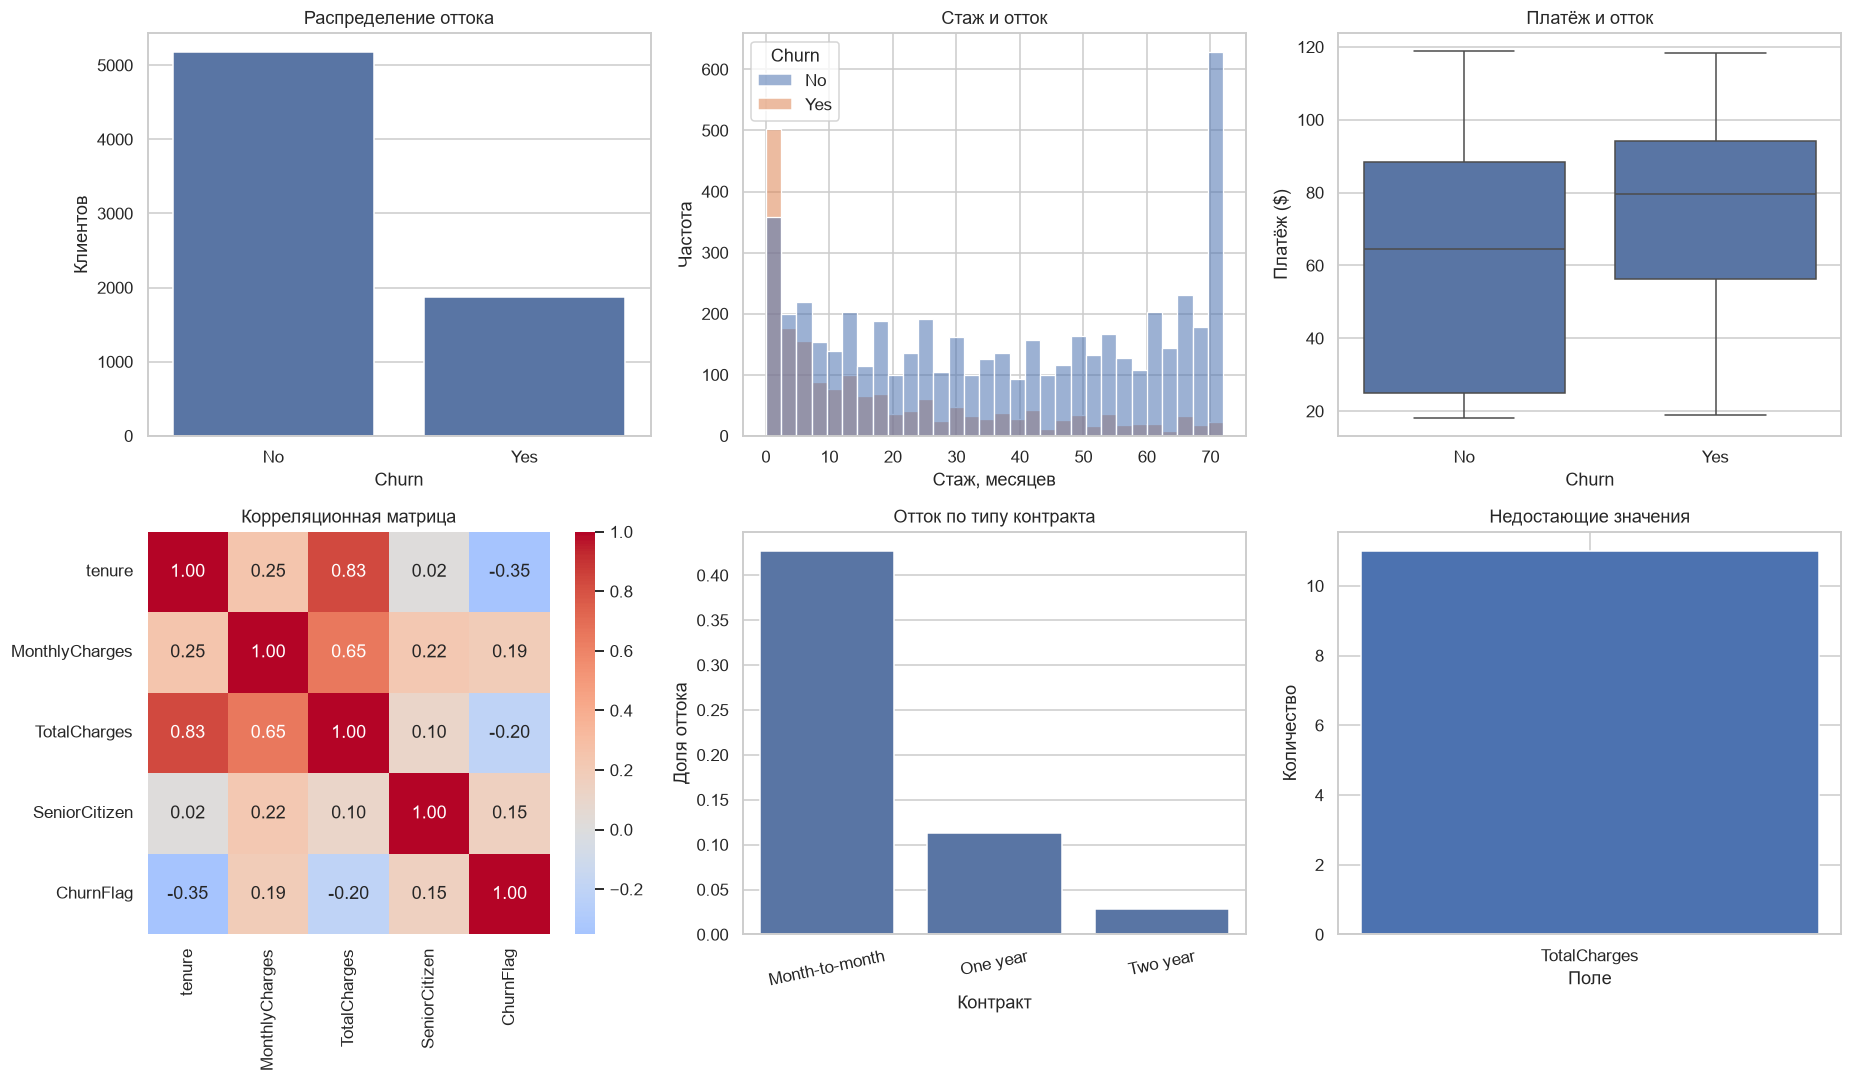

Доля оттока по контрактам (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

Доля оттока по типам интернета (%):
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: ChurnFlag, dtype: float64


In [35]:
# Для графиков используем исходные наблюдения без масштабирования.
plot_df = df.copy()
plot_df['TotalCharges'] = pd.to_numeric(plot_df['TotalCharges'], errors='coerce')
plot_df['ChurnFlag'] = (plot_df['Churn'] == 'Yes').astype(int)
fig, ax = plt.subplots(2, 3, figsize=(17, 10))

# 1. Соотношение оставшихся и ушедших клиентов.
sns.countplot(data=plot_df, x='Churn', order=['No', 'Yes'], color='#4c72b0', ax=ax[0, 0])
ax[0, 0].set(title='Распределение оттока', xlabel='Churn', ylabel='Клиентов')

# 2. Распределение времени пользования по классам.
sns.histplot(data=plot_df, x='tenure', hue='Churn', bins=30, ax=ax[0, 1], alpha=0.55)
ax[0, 1].set(title='Стаж и отток', xlabel='Стаж, месяцев', ylabel='Частота')

# 3. Сравнение ежемесячного платежа.
sns.boxplot(data=plot_df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], color='#4c72b0', ax=ax[0, 2])
ax[0, 2].set(title='Платёж и отток', xlabel='Churn', ylabel='Платёж ($)')

# 4. Корреляции числовых величин и целевой переменной.
correlations = plot_df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].corr()
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1, 0])
ax[1, 0].set_title('Корреляционная матрица')

# 5. Доля оттока по типу договора.
contract_rate = plot_df.groupby('Contract')['ChurnFlag'].mean().sort_values(ascending=False)
sns.barplot(x=contract_rate.index, y=contract_rate.values, color='#4c72b0', ax=ax[1, 1])
ax[1, 1].set(title='Отток по типу контракта', xlabel='Контракт', ylabel='Доля оттока')
ax[1, 1].tick_params(axis='x', rotation=12)

# 6. Пропуски с учётом пустых значений TotalCharges.
missing_active = missing[missing > 0].sort_values(ascending=False)
ax[1, 2].bar(missing_active.index, missing_active.values)
ax[1, 2].set(title='Недостающие значения', xlabel='Поле', ylabel='Количество')
fig.tight_layout()
fig.savefig('examples/eda_plots.png', dpi=170, bbox_inches='tight')
plt.show()

# Для дополнительных наблюдений используем групповые средние, не догадки.
print('Доля оттока по контрактам (%):')
print((contract_rate * 100).round(1).to_string())
print('\nДоля оттока по типам интернета (%):')
print((plot_df.groupby('InternetService')['ChurnFlag'].mean() * 100).round(1))

На диаграмме классов видно, что ушедших заметно меньше оставшихся. Гистограмма стажа помогает проверить, связаны ли первые месяцы обслуживания с повышенным риском. Boxplot полезен для сравнения платежей и выбросов, тепловая карта — для оценки корреляций, столбчатая диаграмма — для сравнения групп договоров. Ниже точные доли считаются напрямую из исходной таблицы, а не оцениваются по высоте столбцов. Эти закономерности **описательные**, сами по себе они не доказывают причин оттока.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Сервисные поля нужны для подсчёта подключённых услуг.
SERVICE_COLS = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]

def make_features(raw):
    """Создать признаки из исходной таблицы без использования целевой переменной."""
    z = raw.drop(columns=['customerID', 'Churn'], errors='ignore').copy()
    z['TotalCharges'] = pd.to_numeric(z['TotalCharges'], errors='coerce')
    z['TenureYears'] = z['tenure'] / 12
    z['AvgMonthlyCharge'] = z['TotalCharges'] / (z['tenure'] + 1)
    z['IsNewClient'] = (z['tenure'] <= 6).astype(int)
    z['HasMultipleServices'] = z[SERVICE_COLS].eq('Yes').sum(axis=1)
    return z

# Stratify сохраняет долю ушедших в обучающей и тестовой части.
y = (df['Churn'] == 'Yes').astype(int)
X_raw = make_features(df)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=SEED, stratify=y
)

# Все настройки предобработки вычисляются только по X_train_raw.
feature_cols = X_train_raw.columns.tolist()
cat_cols = X_train_raw.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = [col for col in feature_cols if col not in cat_cols]
num_medians = X_train_raw[num_cols].median().fillna(0).to_dict()
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    le.fit(X_train_raw[col].fillna('Unknown').astype(str))
    label_encoders[col] = le

# StandardScaler применяется только к числовым колонкам.
scaler = StandardScaler()
scaler.fit(X_train_raw[num_cols].fillna(num_medians))

def transform_features(features, cols, encoders, numeric_medians, fitted_scaler, numeric_cols):
    """Применить сохранённые преобразования и сохранить порядок колонок."""
    z = features.reindex(columns=cols).copy()
    z[numeric_cols] = z[numeric_cols].apply(pd.to_numeric, errors='coerce')
    z[numeric_cols] = z[numeric_cols].fillna(numeric_medians)
    z[numeric_cols] = fitted_scaler.transform(z[numeric_cols])
    for col, le in encoders.items():
        categories = {label: idx for idx, label in enumerate(le.classes_)}
        z[col] = z[col].fillna('Unknown').astype(str).map(categories).fillna(-1).astype(int)
    return z[cols].astype(float)

# Идентичная функция применяется к hold-out и к новым клиентам.
X_train = transform_features(X_train_raw, feature_cols, label_encoders, num_medians, scaler, num_cols)
X_test = transform_features(X_test_raw, feature_cols, label_encoders, num_medians, scaler, num_cols)
assert list(X_train.columns) == list(X_test.columns) == feature_cols
assert X_train.notna().sum().sum() == X_train.size
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Пропусков после обработки:', X_train.isna().sum().sum(), X_test.isna().sum().sum())
print('Количество признаков:', len(feature_cols))

Train: (5634, 23) Test: (1409, 23)
Пропусков после обработки: 0 0
Количество признаков: 23


## 6. Построение и обучение моделей

Для сравнения используются четыре ансамбля с фиксированным `random_state=42`. Random Forest строит независимые деревья, а XGBoost, LightGBM и CatBoost последовательно корректируют ошибки композиции. Классы несбалансированы; поэтому у RF, LightGBM и CatBoost включены веса классов, у XGBoost — `scale_pos_weight` по соотношению классов в обучении. Время обучения фиксируется отдельно, чтобы сравнение включало вычислительные затраты.

In [37]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Доля отрицательного и положительного класса в train определяет вес XGBoost.
pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight='balanced',
        random_state=SEED, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=pos_weight,
        random_state=SEED, eval_metric='logloss', n_jobs=2
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=200, num_leaves=31, max_depth=7,
        learning_rate=0.05, class_weight='balanced',
        random_state=SEED, verbose=-1, n_jobs=2
    ),
    'CatBoost': CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        auto_class_weights='Balanced', random_seed=SEED,
        verbose=False, thread_count=2
    ),
}

# Каждой модели передаётся одинаковая обучающая таблица.
training_times = {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_train, y_train)
    training_times[name] = time.perf_counter() - started
    print(f'{name:14s}: {training_times[name]:.3f} сек')

rf_model = models['Random Forest']
xgb_model = models['XGBoost']
lgbm_model = models['LightGBM']
cat_model = models['CatBoost']

Random Forest : 0.335 сек
XGBoost       : 0.211 сек
LightGBM      : 0.119 сек
CatBoost      : 0.569 сек


## 7. Оценка качества

В качестве итогового теста используется 20% данных, которые не применялись для обучения и настройки преобразований. Считаются `Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`, а также выводятся классификационные отчёты. ROC-AUC вычисляется **по вероятностям**, не по бинарным предсказаниям. Матрица ошибок показывает четыре исхода: TN, FP, FN и TP.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train sec
3,CatBoost,0.756565,0.529190,0.751337,0.620994,0.840434,0.569
0,Random Forest,0.764372,0.540076,0.756684,0.630290,0.838725,0.335
2,LightGBM,0.757984,0.531549,0.743316,0.619844,0.836843,0.119
1,XGBoost,0.771469,0.553719,0.716578,0.624709,0.829164,0.211


Лучшая базовая модель: CatBoost
              precision    recall  f1-score   support

     Остался       0.89      0.76      0.82      1035
        Ушёл       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



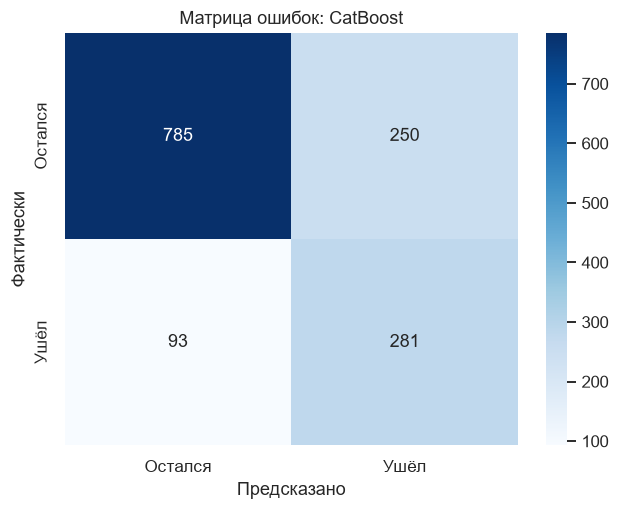

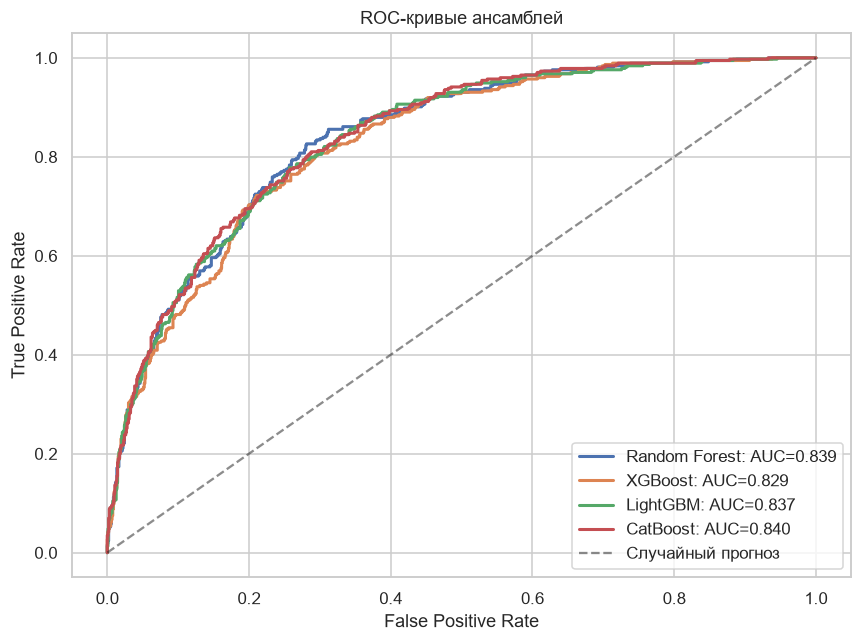

In [38]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

def evaluate_model(model, features, target, name, fit_time=None):
    """Рассчитать показатели классификации на одной и той же выборке."""
    prediction = np.asarray(model.predict(features)).astype(int).ravel()
    probability = model.predict_proba(features)[:, 1]
    return {
        'Model': name,
        'Accuracy': float(accuracy_score(target, prediction)),
        'Precision': float(precision_score(target, prediction, zero_division=0)),
        'Recall': float(recall_score(target, prediction, zero_division=0)),
        'F1': float(f1_score(target, prediction, zero_division=0)),
        'ROC-AUC': float(roc_auc_score(target, probability)),
        'Train sec': fit_time,
    }

# Сортируем таблицу по основному критерию ROC-AUC.
results = [evaluate_model(model, X_test, y_test, name, training_times[name])
           for name, model in models.items()]
results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)
display(results_df.style.format({k: '{:.4f}' for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}).format({'Train sec': '{:.3f}'}))
baseline_winner_name = results_df.iloc[0]['Model']
baseline_winner = models[baseline_winner_name]
print('Лучшая базовая модель:', baseline_winner_name)
print(classification_report(y_test, baseline_winner.predict(X_test), target_names=['Остался', 'Ушёл']))

# Матрица ошибок строится для модели с максимальным тестовым ROC-AUC.
fig, ax = plt.subplots(figsize=(6, 4.8))
cm = confusion_matrix(y_test, baseline_winner.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
ax.set(title=f'Матрица ошибок: {baseline_winner_name}', xlabel='Предсказано', ylabel='Фактически')
fig.tight_layout()
fig.savefig('examples/confusion_matrix.png', dpi=170, bbox_inches='tight')
plt.show()

# ROC-кривые показываем для всех четырёх моделей одновременно.
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    ax.plot(fpr, tpr, lw=2, label=f'{name}: AUC={roc_auc_score(y_test, probability):.3f}')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Случайный прогноз')
ax.set(title='ROC-кривые ансамблей', xlabel='False Positive Rate', ylabel='True Positive Rate')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('examples/roc_curves.png', dpi=170, bbox_inches='tight')
plt.show()

## 8. Интерпретация и бизнес-инсайты

Важности признаков в деревьях отражают степень участия признака в построении разделений, а не причинную силу его влияния. Дополнительно сравню наблюдаемую частоту ухода в понятных бизнес-группах: по типам договора, длительности обслуживания и наличию дополнительных услуг.

,Feature,Random Forest,LightGBM
17,MonthlyCharges,0.096372,1137
18,TotalCharges,0.084676,1013
20,AvgMonthlyCharge,0.088072,886
4,tenure,0.094013,839
16,PaymentMethod,0.032632,324
14,Contract,0.145106,198
0,gender,0.012556,169
15,PaperlessBilling,0.018443,112
22,HasMultipleServices,0.023668,105
6,MultipleLines,0.011981,104


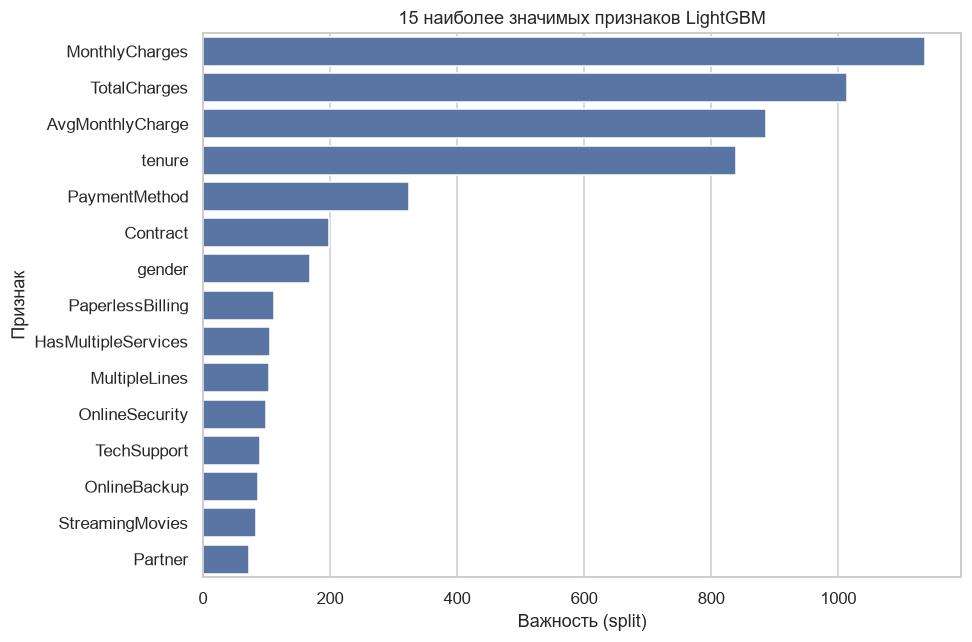

Отток по договору (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnBinary, dtype: float64

Отток среди новых и остальных (%):
tenure
False    19.5
True     52.9
Name: ChurnBinary, dtype: float64

Отток при наличии технической поддержки (%):
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: ChurnBinary, dtype: float64


In [39]:
# Важность Random Forest и LightGBM рассчитана на одинаковом пространстве признаков.
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Random Forest': rf_model.feature_importances_,
    'LightGBM': lgbm_model.feature_importances_,
}).sort_values('LightGBM', ascending=False)
display(importances.head(15))

# График топ-15 по LightGBM — фактические значения из обученной модели.
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=importances.head(15), x='LightGBM', y='Feature', color='#4c72b0', ax=ax)
ax.set(title='15 наиболее значимых признаков LightGBM', xlabel='Важность (split)', ylabel='Признак')
fig.tight_layout()
fig.savefig('examples/feature_importance.png', dpi=170, bbox_inches='tight')
plt.show()

# Наблюдаемые доли — описательная статистика, не эффект рекламной акции.
insights = df.assign(ChurnBinary=y)
print('Отток по договору (%):')
print((insights.groupby('Contract')['ChurnBinary'].mean() * 100).round(1))
print('\nОтток среди новых и остальных (%):')
print((insights.groupby(insights['tenure'].le(6))['ChurnBinary'].mean() * 100).round(1))
print('\nОтток при наличии технической поддержки (%):')
print((insights.groupby('TechSupport')['ChurnBinary'].mean() * 100).round(1))

**Практические выводы:** компания может начать с анализа клиентов с помесячным договором и небольшим стажем, отдельно проверяя группы с высокой долей оттока. Высокая модельная важность `Contract`, `tenure` или `MonthlyCharges` показывает связь с прогнозом, но не означает, что изменение одного поля само по себе удержит клиента. Для проверки эффективности предложений об удержании потребуется отдельный эксперимент, например A/B-тест.

## 9. Тюнинг гиперпараметров (Optuna)

Настрою LightGBM с помощью **30 испытаний TPE**. Целевая функция — средняя ROC-AUC на пятикратной `StratifiedKFold` внутри обучающей выборки. Тестовая выборка не используется при подборе конфигурации. Обучающаяся модель получает фиксированный набор закодированных признаков, поэтому при практическом использовании более строгая схема могла бы включать обучение преобразований внутри каждой CV-складки.

In [40]:
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Количество испытаний соответствует рекомендуемому уровню в задании.
N_TRIALS = 30
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Средняя ROC-AUC LightGBM по пяти обучающим CV-складкам."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    candidate = LGBMClassifier(
        **params, class_weight='balanced', random_state=SEED,
        verbose=-1, n_jobs=1
    )
    scores = cross_val_score(candidate, X_train, y_train, cv=CV,
                             scoring='roc_auc', n_jobs=1)
    return float(np.mean(scores))

# Генератор TPE с фиксированным seed делает поиск воспроизводимым.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
start_tuning = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
tuning_time_sec = time.perf_counter() - start_tuning
print('Лучшая средняя CV ROC-AUC:', round(study.best_value, 4))
print('Лучшие параметры:', json.dumps(study.best_params, indent=2, ensure_ascii=False))

# Повторно обучаем tuned LightGBM на всей обучающей части.
best_lgbm = LGBMClassifier(
    **study.best_params, class_weight='balanced', random_state=SEED,
    verbose=-1, n_jobs=2
)
t0 = time.perf_counter()
best_lgbm.fit(X_train, y_train)
tuned_training_time = time.perf_counter() - t0
tuned_result = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)', tuned_training_time)
baseline_auc = next(r['ROC-AUC'] for r in results if r['Model'] == 'LightGBM')
print(f'Baseline LightGBM ROC-AUC (test): {baseline_auc:.4f}')
print(f'Optuna LightGBM ROC-AUC (test):   {tuned_result["ROC-AUC"]:.4f}')
print(f'Разница (test): {tuned_result["ROC-AUC"] - baseline_auc:+.4f}')
display(pd.DataFrame([tuned_result]))

Лучшая средняя CV ROC-AUC: 0.8494
Лучшие параметры: {
  "n_estimators": 350,
  "num_leaves": 90,
  "max_depth": 3,
  "learning_rate": 0.022943298923083385,
  "subsample": 0.6236369825139823,
  "colsample_bytree": 0.5164731483152039,
  "min_child_samples": 35,
  "reg_alpha": 0.002886956542416407,
  "reg_lambda": 7.328751913955659
}
Baseline LightGBM ROC-AUC (test): 0.8368
Optuna LightGBM ROC-AUC (test):   0.8479
Разница (test): +0.0111


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train sec
0,LightGBM (Optuna),0.740951,0.50764,0.799465,0.620976,0.847926,0.171882


## 10. Интерпретация через SHAP

Для выбранной в задании настроенной LightGBM рассчитаю SHAP-вклады на подвыборке тестовых клиентов. **Summary plot** показывает глобальную картину, **waterfall** — вклад признаков в риск одного клиента, **dependence plot** — изменение вклада наиболее значимого признака. SHAP для деревьев обычно выражается во внутренней шкале модели (часто в логарифме шансов), поэтому **значение SHAP нельзя напрямую читать как процентные пункты вероятности ухода**.

Размер массива SHAP: (200, 23)


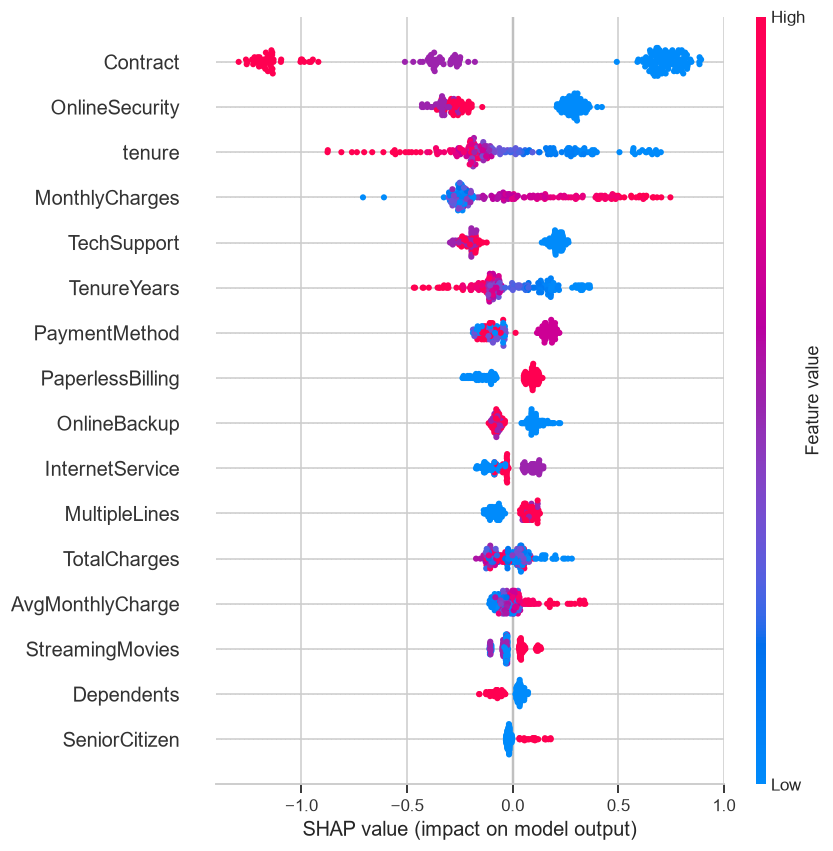

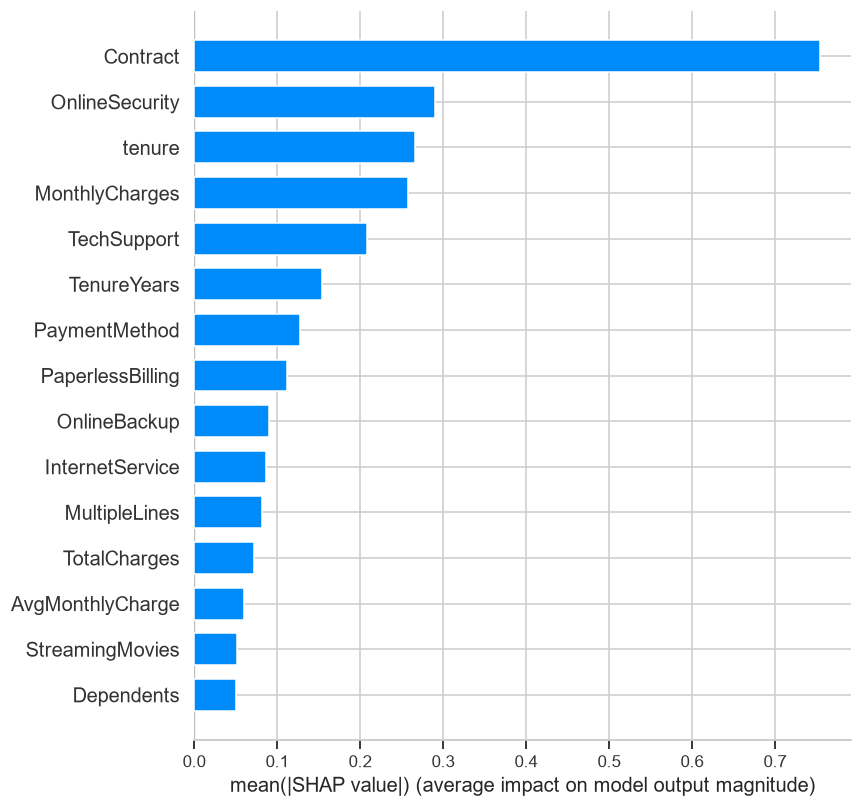

Максимальный риск в подвыборке: 94.2%


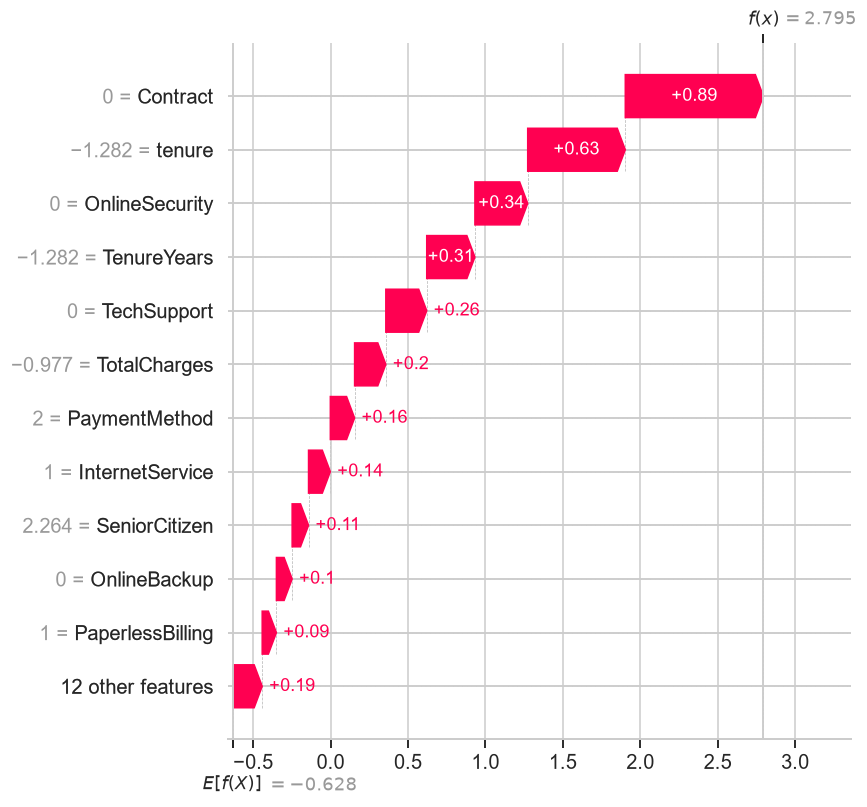

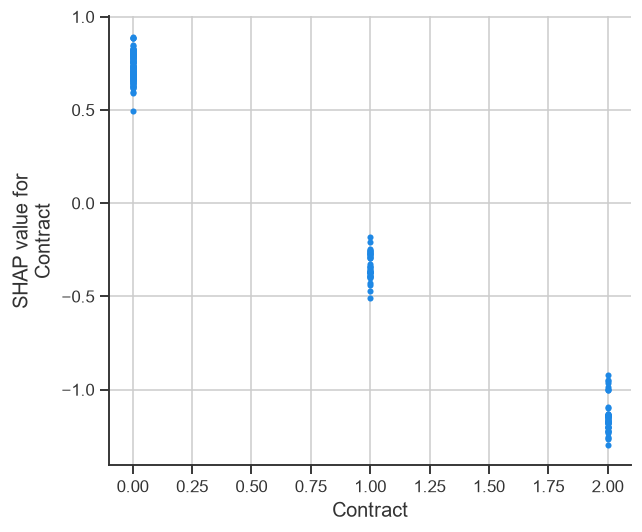

Признак для зависимости SHAP: Contract


In [41]:
import shap

# Подвыборка сокращает время построения объяснений, seed сохраняет состав.
X_shap = X_test.sample(n=min(200, len(X_test)), random_state=SEED)
explainer = shap.TreeExplainer(best_lgbm)
raw_expl = explainer(X_shap)

# SHAP для разных версий иногда возвращает отдельное измерение классов.
values = np.asarray(raw_expl.values)
base_values = np.asarray(raw_expl.base_values)
if values.ndim == 3:
    values = values[:, :, 1]
    if base_values.ndim == 2:
        base_values = base_values[:, 1]
if base_values.ndim == 0:
    base_values = np.repeat(float(base_values), len(X_shap))

# Формируем единый Explanation для beeswarm и waterfall.
explanations = shap.Explanation(
    values=values, base_values=base_values,
    data=X_shap.to_numpy(), feature_names=feature_cols
)
print('Размер массива SHAP:', values.shape)

# Глобальное распределение эффектов и рейтинг признаков.
plt.figure(figsize=(10, 7))
shap.summary_plot(values, X_shap, max_display=16, show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=170, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 7))
shap.summary_plot(values, X_shap, plot_type='bar', max_display=15, show=False)
plt.tight_layout()
plt.savefig('examples/shap_bar.png', dpi=170, bbox_inches='tight')
plt.show()

# Объясняем клиента с максимальным предсказанным риском среди выбранных.
risks = best_lgbm.predict_proba(X_shap)[:, 1]
worst_idx = int(np.argmax(risks))
print(f'Максимальный риск в подвыборке: {risks[worst_idx]:.1%}')
shap.plots.waterfall(explanations[worst_idx], max_display=12, show=False)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=170, bbox_inches='tight')
plt.show()

# Наиболее значимый по абсолютным SHAP признак выбран из результатов расчёта.
top_feature_index = int(np.argmax(np.abs(values).mean(axis=0)))
top_feature = feature_cols[top_feature_index]
shap.dependence_plot(top_feature, values, X_shap, interaction_index=None, show=False)
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=170, bbox_inches='tight')
plt.show()
print('Признак для зависимости SHAP:', top_feature)

По цвету и расположению точек summary plot можно установить, при каких значениях характеристик модель повышает или понижает оценку риска. Waterfall относится к **одному** наблюдению, поэтому нельзя переносить его вклады на всех клиентов. Это объяснение прогнозов, а не свидетельство того, что изменение договора автоматически изменит отток на конкретную величину.

## 11. Сохранение модели и метаданных

Сохраняю все четыре базовые модели и настроенную LightGBM, плюс масштабировщик, кодировщики, порядок признаков и словарь обучающих медиан. Такой набор необходим, чтобы повторное предсказание обрабатывало нового клиента так же, как обучение.

In [42]:
# Одинаковые имена файлов и каталогов с указанными в методичке.
filenames = {
    'rf_model.pkl': rf_model,
    'xgb_model.pkl': xgb_model,
    'lgbm_model.pkl': lgbm_model,
    'cat_model.pkl': cat_model,
    'best_model.pkl': best_lgbm,
    'scaler.pkl': scaler,
    'label_encoders.pkl': label_encoders,
}
for filename, obj in filenames.items():
    joblib.dump(obj, Path('models') / filename, compress=3)

# Порядок признаков и метаданные предобработки сохраняются в JSON.
Path('models/feature_cols.json').write_text(
    json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8'
)
preprocess_config = {'num_cols': num_cols,
                     'num_medians': {k: float(v) for k, v in num_medians.items()},
                     'cat_cols': cat_cols,
                     'service_cols': SERVICE_COLS}
Path('models/preprocess_config.json').write_text(
    json.dumps(preprocess_config, ensure_ascii=False, indent=2), encoding='utf-8'
)

# JSON содержит фактически рассчитанные показатели и дату расчёта.
metrics = {
    'dataset': 'Telco Customer Churn',
    'n_rows': len(df),
    'random_state': SEED,
    'n_trials': N_TRIALS,
    'test_size': len(X_test),
    'models': {r['Model']: {k: v for k, v in r.items() if k != 'Model'}
               for r in results + [tuned_result]},
    'optuna_best_cv_roc_auc': float(study.best_value),
    'optuna_best_params': study.best_params,
    'optuna_tuning_time_sec': float(tuning_time_sec),
    'saved_best_model': 'LightGBM (Optuna)'
}
Path('models/metrics.json').write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Сохранено моделей:', len(filenames) - 2)
print('Метаданные:', list(Path('models').iterdir()))

Сохранено моделей: 5
Метаданные: [WindowsPath('models/.gitkeep'), WindowsPath('models/best_model.pkl'), WindowsPath('models/cat_model.pkl'), WindowsPath('models/feature_cols.json'), WindowsPath('models/label_encoders.pkl'), WindowsPath('models/lgbm_model.pkl'), WindowsPath('models/metrics.json'), WindowsPath('models/preprocess_config.json'), WindowsPath('models/rf_model.pkl'), WindowsPath('models/scaler.pkl'), WindowsPath('models/xgb_model.pkl')]


## 12. Загрузка модели из репозитория и проверка


In [46]:
# Сначала проверяем, что сериализация не изменила прогноз трёх клиентов.
local_model = joblib.load('models/best_model.pkl')
local_features = json.loads(Path('models/feature_cols.json').read_text(encoding='utf-8'))
assert local_features == feature_cols
check_rows = X_test.iloc[:3][feature_cols]
original_proba = best_lgbm.predict_proba(check_rows)[:, 1]
loaded_proba = local_model.predict_proba(check_rows)[:, 1]
assert np.allclose(original_proba, loaded_proba, rtol=1e-10, atol=1e-10)
print('Локальная загрузка и сравнение трёх прогнозов — успешно')
print('Вероятности:', np.round(loaded_proba, 5))

# Включить после публикации моделей в публичном GitHub-репозитории.
GITHUB_RAW_BASE = (
    'https://raw.githubusercontent.com/CherepanovVyacheslav/'
    'ml-course-cherepanov/main/module-3-churn'
)
CHECK_GITHUB = True

if CHECK_GITHUB:
    def fetch_trusted_file(name):
        """Скачать файл из личного репозитория; HTTP-ошибки не скрывать."""
        url = f'{GITHUB_RAW_BASE}/models/{name}'
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        return response.content

    # Подтвердите доверие к опубликованному .pkl прежде чем десериализовать.
    remote_model = joblib.load(BytesIO(fetch_trusted_file('best_model.pkl')))
    remote_features = json.loads(fetch_trusted_file('feature_cols.json').decode('utf-8'))
    assert remote_features == feature_cols
    remote_probs = remote_model.predict_proba(check_rows)[:, 1]
    assert np.allclose(remote_probs, original_proba, rtol=1e-10, atol=1e-10)
    print('GitHub raw: модель и три прогноза подтверждены')
else:
    print('Проверка GitHub отключена до публикации файлов: CHECK_GITHUB = False')

Локальная загрузка и сравнение трёх прогнозов — успешно
Вероятности: [0.06501 0.88601 0.22404]
GitHub raw: модель и три прогноза подтверждены


In [47]:
# Пять разных клиентов из тестовой выборки: сравнение всех ансамблей.
examples_five = X_test.iloc[:5].copy()
comparison = pd.DataFrame(index=examples_five.index)
comparison['Факт: уход'] = y_test.loc[examples_five.index].values
for name, model in list(models.items()) + [('LightGBM (Optuna)', best_lgbm)]:
    comparison[name] = model.predict_proba(examples_five)[:, 1]
print('Вероятность ухода для пяти клиентов (0–1):')
display(comparison.round(3))


Вероятность ухода для пяти клиентов (0–1):


,Факт: уход,Random Forest,XGBoost,LightGBM,CatBoost,LightGBM (Optuna)
437,0,0.010,0.007,0.008,0.030,0.065
2280,0,0.892,0.944,0.929,0.936,0.886
2235,0,0.139,0.174,0.187,0.130,0.224
4460,0,0.452,0.397,0.355,0.468,0.535
3761,0,0.029,0.002,0.013,0.024,0.036


## 13. Выводы

**Что выполнено.** Подготовлена воспроизводимая схема классификации оттока: исследование распределений и пропусков, разработка признаков, сравнение четырёх ансамблей, подбор LightGBM через 30 испытаний Optuna и интерпретация SHAP. Фактические значения ROC-AUC, Precision, Recall и F1 представлены в расчётных таблицах разделов 7 и 9. Модель для публикации — настроенная LightGBM, при этом отдельное сравнение показывает, действительно ли она лучше базовых вариантов.

**Основные трудности.** В датасете присутствует дисбаланс классов; в `TotalCharges` есть текстовые пробелы; закодированные категории требуют строгого сохранения схемы преобразований. SHAP показывает модельную зависимость, а не причинность. Данные содержат однократный снимок клиентов, поэтому для настоящего временного прогноза желательно иметь исторические последовательные выгрузки.

**Возможные улучшения:**
1. Добавить взаимодействия длительности договора, стажа и стоимости услуг.
2. Сравнить ансамбль Stacking из четырёх алгоритмов с каждой одиночной моделью.
3. Проверить SMOTE **внутри CV-складок**, не до разделения данных.
4. Версионировать признаки и их преобразования через Feature Store.
5. Калибровать вероятности и выбирать порог с учётом расходов на удержание.
6. Провести временную валидацию при наличии помесячных данных.
7. Проверить стабильность модели на новых группах клиентов и изменение распределений.

**Итог:** модель полезна для ранжирования клиентов по риску, но решения об удержании следует проверять через бизнес-метрики и контролируемые эксперименты.

## 14. Список источников и приложение

1. Breiman, L. (2001). [Random Forests](https://doi.org/10.1023/A:1010933404324). *Machine Learning*, 45, 5–32.
2. Chen, T., Guestrin, C. (2016). [XGBoost: A Scalable Tree Boosting System](https://doi.org/10.1145/2939672.2939785). *KDD*.
3. Ke, G. et al. (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html). *NeurIPS*.
4. Prokhorenkova, L. et al. (2018). [CatBoost: unbiased boosting with categorical features](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51da7c85c9f059d69e4c-Abstract.html). *NeurIPS*.
5. Lundberg, S., Lee, S.-I. (2017). [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874). *NeurIPS*.
6. Akiba, T. et al. (2019). [Optuna: A Next-generation Hyperparameter Optimization Framework](https://arxiv.org/abs/1907.10902). *KDD*.
7. [Telco Customer Churn — Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
8. [Документация scikit-learn](https://scikit-learn.org/stable/), [Optuna](https://optuna.readthedocs.io/en/stable/), [SHAP](https://shap.readthedocs.io/en/latest/).
